In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    average_precision_score,
    roc_auc_score
)

In [12]:
from pathlib import Path

ham_path = Path("../data/raw/easy_ham/easy_ham")
spam_path = Path("../data/raw/spam/spam")

ham_files = list(ham_path.iterdir())
spam_files = list(spam_path.iterdir())

print("Ham emails:", len(ham_files))
print("Spam emails:", len(spam_files))

Ham emails: 2501
Spam emails: 501


In [13]:
with open(ham_files[0], "rb") as f:
    email = f.read()

print(email[:2000])

b'From exmh-workers-admin@redhat.com  Thu Aug 22 12:36:23 2002\nReturn-Path: <exmh-workers-admin@spamassassin.taint.org>\nDelivered-To: zzzz@localhost.netnoteinc.com\nReceived: from localhost (localhost [127.0.0.1])\n\tby phobos.labs.netnoteinc.com (Postfix) with ESMTP id D03E543C36\n\tfor <zzzz@localhost>; Thu, 22 Aug 2002 07:36:16 -0400 (EDT)\nReceived: from phobos [127.0.0.1]\n\tby localhost with IMAP (fetchmail-5.9.0)\n\tfor zzzz@localhost (single-drop); Thu, 22 Aug 2002 12:36:16 +0100 (IST)\nReceived: from listman.spamassassin.taint.org (listman.spamassassin.taint.org [66.187.233.211]) by\n    dogma.slashnull.org (8.11.6/8.11.6) with ESMTP id g7MBYrZ04811 for\n    <zzzz-exmh@spamassassin.taint.org>; Thu, 22 Aug 2002 12:34:53 +0100\nReceived: from listman.spamassassin.taint.org (localhost.localdomain [127.0.0.1]) by\n    listman.redhat.com (Postfix) with ESMTP id 8386540858; Thu, 22 Aug 2002\n    07:35:02 -0400 (EDT)\nDelivered-To: exmh-workers@listman.spamassassin.taint.org\nRecei

In [14]:
from email import policy
from email.parser import BytesParser

In [15]:
parsed_email = BytesParser(policy=policy.default).parsebytes(email)

In [16]:
print(parsed_email['From'])
print(parsed_email['Subject'])
print(parsed_email['Date'])

Robert Elz <kre@munnari.OZ.AU>
Re: New Sequences Window
Thu, 22 Aug 2002 18:26:25 +0700


In [17]:
body = parsed_email.get_body(preferencelist=("plain",))

if body:
    content = body.get_content()
    print(content)

    Date:        Wed, 21 Aug 2002 10:54:46 -0500
    From:        Chris Garrigues <cwg-dated-1030377287.06fa6d@DeepEddy.Com>
    Message-ID:  <1029945287.4797.TMDA@deepeddy.vircio.com>


  | I can't reproduce this error.

For me it is very repeatable... (like every time, without fail).

This is the debug log of the pick happening ...

18:19:03 Pick_It {exec pick +inbox -list -lbrace -lbrace -subject ftp -rbrace -rbrace} {4852-4852 -sequence mercury}
18:19:03 exec pick +inbox -list -lbrace -lbrace -subject ftp -rbrace -rbrace 4852-4852 -sequence mercury
18:19:04 Ftoc_PickMsgs {{1 hit}}
18:19:04 Marking 1 hits
18:19:04 tkerror: syntax error in expression "int ...

Note, if I run the pick command by hand ...

delta$ pick +inbox -list -lbrace -lbrace -subject ftp -rbrace -rbrace  4852-4852 -sequence mercury
1 hit

That's where the "1 hit" comes from (obviously).  The version of nmh I'm
using is ...

delta$ pick -version
pick -- nmh-1.0.4 [compiled on fuchsia.cs.mu.OZ.AU at Sun Mar 17 14:55

In [18]:
print(parsed_email.get_content_type())
print(parsed_email.get_content_disposition())
print(parsed_email.is_multipart())

text/plain
None
False


In [19]:
X = []
y = []

X.extend(ham_files)
y.extend([0] * len(ham_files))

X.extend(spam_files)
y.extend([1] * len(spam_files))

In [20]:
print(len(X))
print(len(y))

3002
3002


In [21]:
from collections import Counter

print(Counter(y))

Counter({0: 2501, 1: 501})


In [22]:
pd.Series(y).value_counts(normalize = True)

0    0.833111
1    0.166889
Name: proportion, dtype: float64

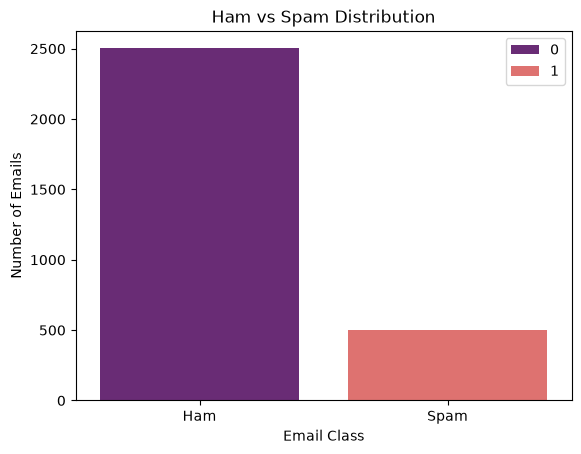

In [23]:
sns.countplot(x=y, hue=y, palette="magma")
plt.xlabel("Email Class")
plt.ylabel("Number of Emails")
plt.title("Ham vs Spam Distribution")
plt.xticks([0,1], ["Ham", "Spam"])
plt.show()

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
print("Training:", Counter(y_train))
print("Test:", Counter(y_test))

Training: Counter({0: 2000, 1: 401})
Test: Counter({0: 501, 1: 100})


In [16]:
train_props = pd.Series(y_train).value_counts(normalize=True)
test_props = pd.Series(y_test).value_counts(normalize=True)

print("Training proportions:\n", train_props)
print("\nTesting proportions:\n", test_props)

Training proportions:
 0    0.832986
1    0.167014
Name: proportion, dtype: float64

Testing proportions:
 0    0.833611
1    0.166389
Name: proportion, dtype: float64


In [17]:
email_path = Path(X_train[0])
print(email_path)
print(email_path.stat())
print(email_path.stat().st_size)





..\data\raw\easy_ham\easy_ham\01212.5f88fb786e44da332e42c578fe657978
os.stat_result(st_mode=33206, st_ino=281474977092153, st_dev=43538030240042410, st_nlink=1, st_uid=0, st_gid=0, st_size=3549, st_atime=1794243217, st_mtime=1046429622, st_ctime=1794021293)
3549


In [18]:
size = (email_path.stat().st_size)/1024
print(size)

3.4658203125


In [19]:
email_sizes = []
for email in X_train:
    email_path = Path(email)
    size = (email_path.stat().st_size)/1024
    email_sizes.append(size)

In [20]:
print(len(email_sizes))
email_sizes[:10]

2401


[3.4658203125,
 8.3095703125,
 1.4140625,
 3.66015625,
 4.291015625,
 1.28515625,
 1.470703125,
 3.9052734375,
 3.681640625,
 1.0986328125]

In [21]:
print(f"Mean : {np.mean(email_sizes)}")
print(f"Median : {np.median(email_sizes)}")
print(f"Minimum : {np.min(email_sizes)}")
print(f"Maximum : {np.max(email_sizes)}")

Mean : 4.1027566638900455
Median : 3.162109375
Minimum : 0.359375
Maximum : 226.9287109375


In [22]:
largest_sizes = np.argsort(email_sizes)[-10:][::-1]
print(largest_sizes)

[ 422 1880 1341 1898  489  714 2007  805 1681 1640]


In [23]:
for index in largest_sizes:
    print(f"Index : {index}, Size : {email_sizes[index]:.2f}KB")

Index : 422, Size : 226.93KB
Index : 1880, Size : 197.75KB
Index : 1341, Size : 181.37KB
Index : 1898, Size : 124.25KB
Index : 489, Size : 88.22KB
Index : 714, Size : 85.82KB
Index : 2007, Size : 71.22KB
Index : 805, Size : 59.27KB
Index : 1681, Size : 48.28KB
Index : 1640, Size : 41.28KB


In [24]:
largest_index = largest_sizes[0]

largest_email_path = Path(X_train[largest_index])

print(largest_email_path)

..\data\raw\spam\spam\00341.99b463b92346291f5848137f4a253966


In [25]:
with open(largest_email_path, "rb") as f:
    largest_email = f.read()

print(largest_email[:2000])

b'From AdvertSpRj40@cs.com  Tue Sep 17 11:41:33 2002\nReturn-Path: <AdvertSpRj40@cs.com>\nDelivered-To: zzzz@localhost.spamassassin.taint.org\nReceived: from localhost (jalapeno [127.0.0.1])\n\tby zzzzason.org (Postfix) with ESMTP id 0948E16F03\n\tfor <zzzz@localhost>; Tue, 17 Sep 2002 11:40:46 +0100 (IST)\nReceived: from jalapeno [127.0.0.1]\n\tby localhost with IMAP (fetchmail-5.9.0)\n\tfor zzzz@localhost (single-drop); Tue, 17 Sep 2002 11:40:46 +0100 (IST)\nReceived: from cs.com (12-245-142-206.client.attbi.com [12.245.142.206])\n    by dogma.slashnull.org (8.11.6/8.11.6) with ESMTP id g8H9cKC04150 for\n    <zzzz@jmason.org>; Tue, 17 Sep 2002 10:38:21 +0100\nMessage-Id: <4174-22002921794043650@cs.com>\nErrors-To: AdvertSpRj40@cs.com\nFrom: "Adverting Department" <AdvertSpRj40@cs.com>\nOrganisation: JOHNSON HOME PRODUCTS & SERVICES\nTo: "zzzz@spamassassin.taint.org" <yyyy@spamassassin.taint.org>\nSubject: May I have a moment of your Time PLEASE\nDate: Tue, 17 Sep 2002 05:40:44 -0400\

In [26]:
parsed_largest = BytesParser(policy=policy.default).parsebytes(largest_email)

print(parsed_largest.is_multipart())
print(parsed_largest.get_content_type())

True
multipart/mixed


In [27]:
for part in parsed_largest.walk():
    print(part.get_content_type(), part.get_filename())

multipart/mixed None
multipart/alternative None
text/plain None
text/html None
image/gif ecp10cc.gif


In [28]:
parts = list(parsed_largest.walk())

print(len(parts))

5


In [29]:
for part in parsed_largest.walk():
    if part.get_filename():
        attachment = part.get_payload(decode=True)
        print(part.get_filename())
        print(len(attachment)/1024, "KB")

ecp10cc.gif
165.0029296875 KB


In [30]:
ham_sizes = []
spam_sizes = []

for email,label in zip(X_train, y_train):

    email_path = Path(email)
    size = (email_path.stat().st_size)/1024

    if label == 0:
        ham_sizes.append(size)
    else:
        spam_sizes.append(size)

In [31]:
print(len(ham_sizes))
print(len(spam_sizes))

2000
401


In [32]:
print("HAM EMAILS")
print("Mean:", np.mean(ham_sizes))
print("Median:", np.median(ham_sizes))
print("Minimum:", np.min(ham_sizes))
print("Maximum:", np.max(ham_sizes))

print("\nSPAM EMAILS")
print("Mean:", np.mean(spam_sizes))
print("Median:", np.median(spam_sizes))
print("Minimum:", np.min(spam_sizes))
print("Maximum:", np.max(spam_sizes))

HAM EMAILS
Mean: 3.4731162109375
Median: 3.0830078125
Minimum: 0.359375
Maximum: 197.75390625

SPAM EMAILS
Mean: 7.243108050187033
Median: 3.93359375
Minimum: 0.84765625
Maximum: 226.9287109375


C:\Users\DELL\AppData\Local\Temp\ipykernel_27828\4124467759.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_sizes, x="Category", y="Email Size (KB)", palette='rocket')


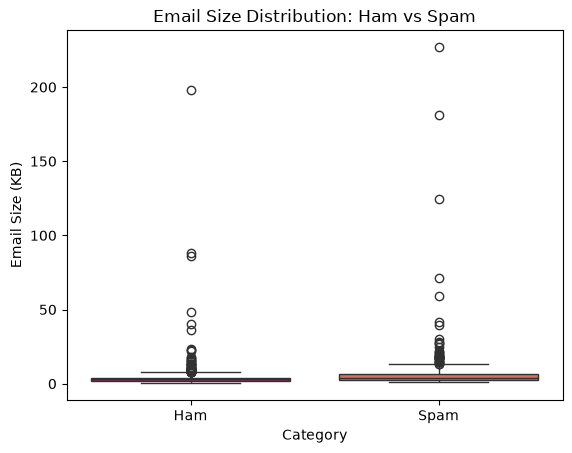

In [33]:
df_sizes = pd.DataFrame({
    "Email Size (KB)": ham_sizes + spam_sizes,
    "Category": ["Ham"] * len(ham_sizes) + ["Spam"] * len(spam_sizes)
})

sns.boxplot(data=df_sizes, x="Category", y="Email Size (KB)", palette='rocket')

plt.title("Email Size Distribution: Ham vs Spam")
plt.show()


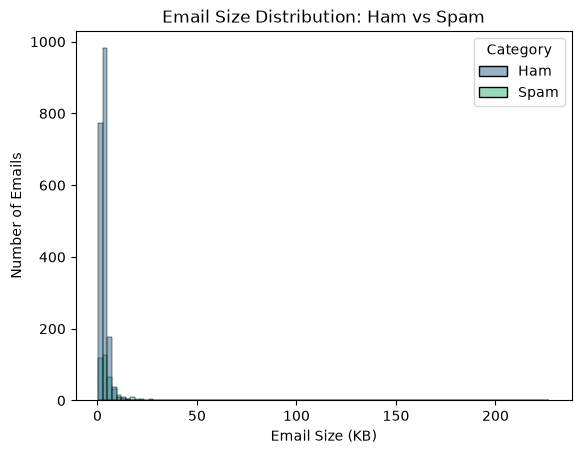

In [34]:
sns.histplot(
    data=df_sizes,
    x="Email Size (KB)",
    hue="Category",
    palette="viridis"
)

plt.title("Email Size Distribution: Ham vs Spam")
plt.xlabel("Email Size (KB)")
plt.ylabel("Number of Emails")
plt.show()

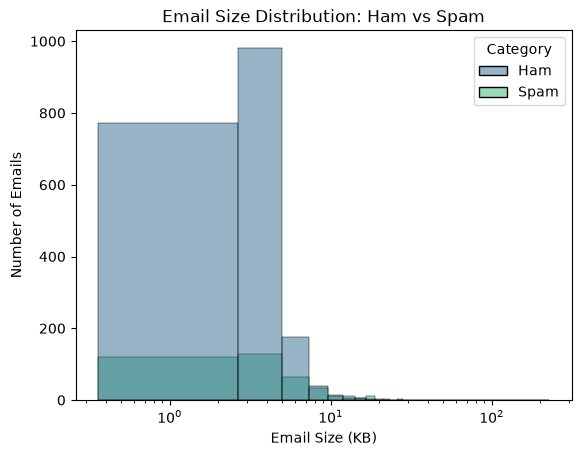

In [35]:
sns.histplot(
    data=df_sizes,
    x="Email Size (KB)",
    hue="Category",
    palette="viridis"
)

plt.title("Email Size Distribution: Ham vs Spam")
plt.xlabel("Email Size (KB)")
plt.ylabel("Number of Emails")
plt.xscale("log")
plt.show()

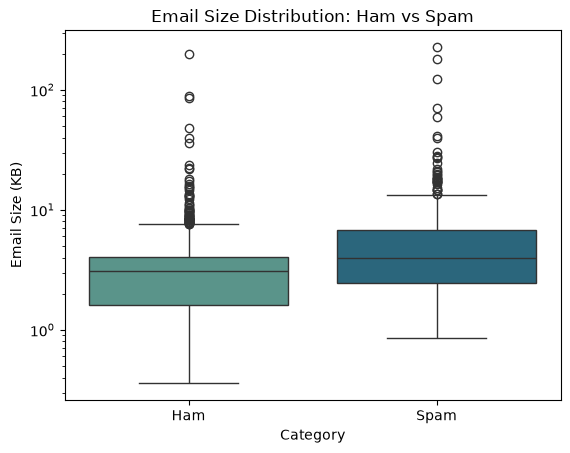

In [36]:
sns.boxplot(
    data=df_sizes,
    x="Category",
    y="Email Size (KB)",
    hue="Category",
    palette="crest",
    legend=False
)

plt.yscale("log")
plt.title("Email Size Distribution: Ham vs Spam")
plt.show()

In [ ]:
def extract_body(email_path):
    with open(email_path, "rb") as f:
        raw_email = f.read()

    parsed = BytesParser(policy=policy.default).parsebytes(raw_email)

    body = parsed.get_body(preferencelist=("plain", "html")) 

    if body is None:
        print("No body found:", email_path)
        return ""

    try:
        return body.get_content()

    except LookupError:
        payload = body.get_payload(decode=True)

        if payload is None:
            return ""

        return payload.decode("utf-8", errors="replace")

In [38]:
ham_body_lengths = []
spam_body_lengths = []

for email, label in zip(X_train, y_train):

    sample_body = extract_body(email)

    if label == 0:
        ham_body_lengths.append(len(sample_body))
    else:
        spam_body_lengths.append(len(sample_body))

No body found: ..\data\raw\spam\spam\00467.5b733c506b7165424a0d4a298e67970f


In [39]:
print(len(ham_body_lengths))
print(len(spam_body_lengths))

2000
401


In [40]:
print(spam_body_lengths[:10])
print(ham_body_lengths[:10])

[1790, 3022, 3944, 1451, 1125, 558, 16295, 3280, 3906, 5186]
[973, 538, 583, 433, 222, 1042, 1674, 197, 296, 1223]


In [41]:
print(f"Mean of body lengths of ham emails : {np.mean(ham_body_lengths)}")
print(f"Median of body lengths of ham emails : {np.median(ham_body_lengths)}")
print(f"Minimum of body lengths of ham emails : {np.min(ham_body_lengths)}")
print(f"Maximum of body lengths of ham emails : {np.max(ham_body_lengths)}")
print()
print(f"Mean of body lengths of spam emails : {np.mean(spam_body_lengths)}")
print(f"Median of body lengths of spam emails : {np.median(spam_body_lengths)}")
print(f"Minimum of body lengths of spam emails : {np.min(spam_body_lengths)}")
print(f"Maximum of body lengths of spam emails : {np.max(spam_body_lengths)}")


Mean of body lengths of ham emails : 1511.835
Median of body lengths of ham emails : 840.5
Minimum of body lengths of ham emails : 47
Maximum of body lengths of ham emails : 202500

Mean of body lengths of spam emails : 3875.1645885286785
Median of body lengths of spam emails : 1793.0
Minimum of body lengths of spam emails : 0
Maximum of body lengths of spam emails : 126335


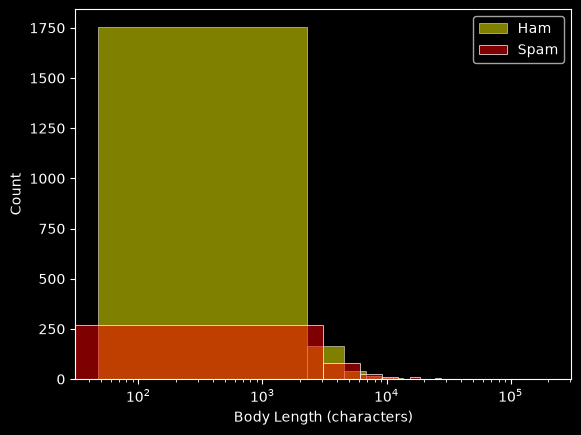

In [53]:
sns.histplot(ham_body_lengths, color="yellow", label="Ham", alpha=0.5)
sns.histplot(spam_body_lengths, color="red", label="Spam", alpha=0.5)

plt.xscale("log")
plt.xlabel("Body Length (characters)")
plt.ylabel("Count")

plt.legend()
plt.show()
# plt.style.use('white_background')

In [43]:
ham_multipart = 0
spam_multipart = 0

for email, label in zip(X_train, y_train):

    email_path = Path(email)
    with open(email_path, "rb") as f:
        parsed_email = f.read()
    parsed = BytesParser(policy=policy.default).parsebytes(parsed_email)

    if parsed.is_multipart():
        if label == 0:
            ham_multipart += 1
        else:
            spam_multipart += 1




In [44]:
print("Ham multipart count : ",ham_multipart)
print("Spam multipart count : ",spam_multipart)
print(f"Ham multipart percentage : {(ham_multipart/len(ham_body_lengths)*100):.2f}%")
print(f"Spam multipart count : {(spam_multipart/len(spam_body_lengths)*100):.2f}%")


Ham multipart count :  73
Spam multipart count :  74
Ham multipart percentage : 3.65%
Spam multipart count : 18.45%


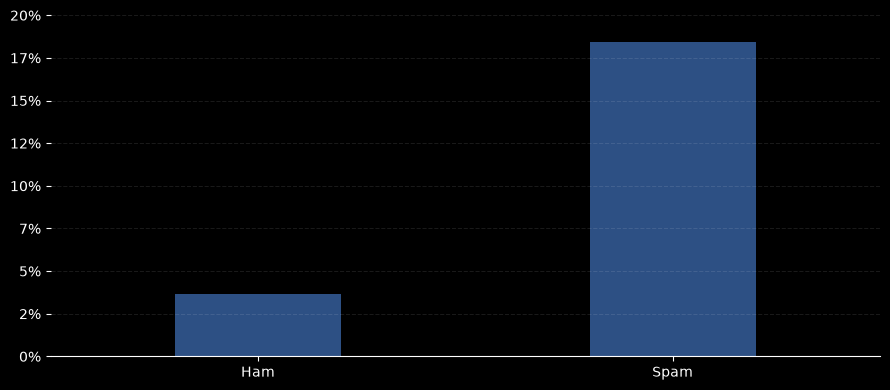

In [ ]:
# Data from your calculations
classes = ['Ham', 'Spam']
percentages = [3.65, 18.45]  # The values matching your output

# Set a dark theme background to match your image
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(9, 4))

# Create the bar chart with custom color and rounded/styled spacing
sns.barplot(x=classes, y=percentages, color='#1e4d92', ax=ax, width=0.4)

# Format the Y-axis to show percentages
ax.set_ylabel('')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{int(y)}%'))
ax.set_ylim(0, 20)  # Sets the scale from 0% to 20% to match your image

# Remove top and right borders for a clean look
sns.despine(top=True, right=True, left=True, bottom=False)

# Add subtle grid lines matching the image
ax.grid(axis='y', linestyle='--', alpha=0.1)

# Display the chart
plt.tight_layout()
plt.show()


In [57]:
ham_attachement = 0
spam_attachement = 0

for email, label in zip(X_train, y_train):

    email_path = Path(email)
    with open(email_path, "rb") as f:
        parsed_email = f.read()
    parsed = BytesParser(policy=policy.default).parsebytes(parsed_email)

    has_attachment = False
    for part in parsed.walk():

        if part.get_content_disposition() == "attachment":
            has_attachment = True
            break

    if has_attachment:
        if label == 0:
            ham_attachement += 1
        else:
            spam_attachement += 1

In [59]:
print(ham_attachement)
print(spam_attachement)

5
5


In [61]:
print(f"No of ham attachments : {(ham_attachement)}")
print(f"No of spam attachments : {(spam_attachement)}")
print(f"Percentage of ham attachments : {(ham_attachement/len(ham_body_lengths)*100):.2f}%")
print(f"Percentage of spam attachments : {(spam_attachement/len(spam_body_lengths)*100):.2f}%")

No of ham attachments : 5
No of spam attachments : 5
Percentage of ham attachments : 0.25%
Percentage of spam attachments : 1.25%


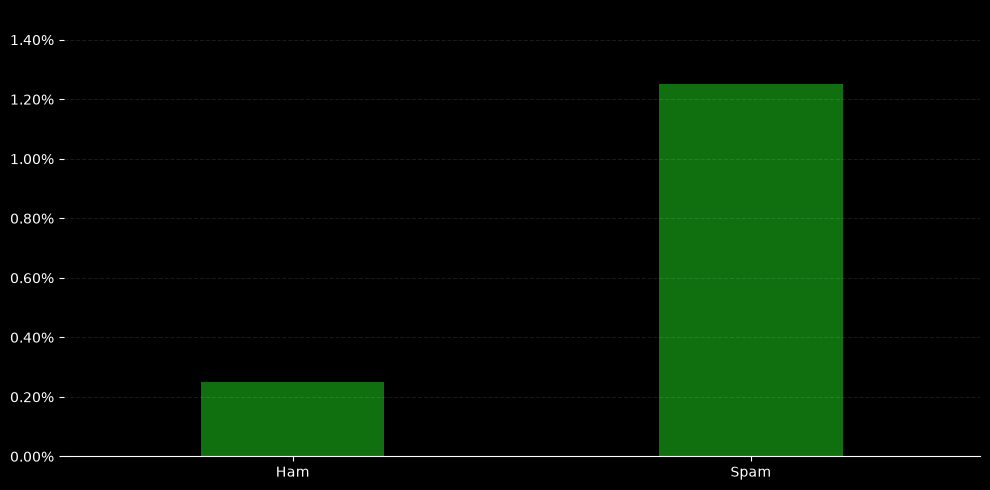

In [71]:


# Data from your calculations
classes = ['Ham', 'Spam']
percentages = [0.25, 1.25]  # Extracted from your text

# Set a dark theme background to match your environment
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(10, 5))

# Create the bar chart using a beautiful baby pink hex code (#FFB6C1)
sns.barplot(x=classes, y=percentages, color="green", ax=ax, width=0.4) # Lavender example

# Format the Y-axis to show percentages
ax.set_ylabel('')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.2f}%'))

# Adjust the Y-limit dynamically to give head-room above the highest bar
ax.set_ylim(0, max(percentages) + 0.25)  

# Remove top, right, and left borders for a clean look
sns.despine(top=True, right=True, left=True, bottom=False)

# Add subtle grid lines matching your dark UI layout
ax.grid(axis='y', linestyle='--', alpha=0.1)

# Display the chart
plt.tight_layout()
plt.show()


In [ ]:
ham_mime_types = {}
spam_mime_types = {}

for email, label in zip(X_train, y_train):

    email_path = Path(email)

    with open(email_path, "rb") as f:
        parsed_email = f.read()
    parsed = BytesParser(policy=policy.default).parsebytes(parsed_email)
    
    for part in parsed.walk():
        mime_type = part.get_content_type()

        if label == 0:
            if mime_type not in ham_mime_types:
                ham_mime_types[mime_type] = 1
            else:
                ham_mime_types[mime_type] += 1

        else:
            if mime_type not in spam_mime_types:
                spam_mime_types[mime_type] = 1
            else:
                spam_mime_types[mime_type] += 1

In [ ]:
print(ham_mime_types)
print(spam_mime_types)

{'text/plain': 2011, 'multipart/signed': 53, 'application/pgp-signature': 51, 'multipart/alternative': 9, 'text/enriched': 1, 'multipart/mixed': 8, 'application/octet-stream': 1, 'application/ms-tnef': 1, 'multipart/report': 2, 'message/delivery-status': 2, 'text/rfc822-headers': 1, 'text/html': 8, 'multipart/related': 2, 'application/x-pkcs7-signature': 2, 'message/rfc822': 2, 'application/x-java-applet': 1}
{'multipart/alternative': 41, 'text/plain': 233, 'text/html': 201, 'multipart/mixed': 34, 'image/gif': 1, 'multipart/related': 7, 'image/jpeg': 3, 'application/octet-stream': 2}


In [75]:
ham_subjects = []
spam_subjects = []

for email, label in zip(X_train, y_train):

    email_path = Path(email)

    with open(email_path, "rb") as f:
        parsed_email = f.read()
    parsed = BytesParser(policy=policy.default).parsebytes(parsed_email)
    
    if label == 0:
        ham_subjects.append(parsed["Subject"])
    else:
        spam_subjects.append(parsed["Subject"])

In [78]:
ham_subjects[:5]

['Re: Gabber packages for 8.0 (was: All set for Red Hat Linux 8.0)',
 'Palm-sized translators going to Iraq',
 'Re: Python 2.2 site libs?',
 'Central',
 'Re: [SAdev] phew!']

In [79]:
spam_subjects[:5]

['Friend,Instantly Copy ANY DVD or Playstation Game with this software......',
 'Get the money you need while mortgage rates are down.',
 'MSNBC: Rates Hit 35 year Low 4.75% ...12021',
 'investment',
 'you can watch me']

In [85]:
subject = spam_subjects[0]

In [82]:
import string

In [92]:
clean_txt = "".join(ch for ch in subject if ch not in string.punctuation)
clean_txt
print(clean_txt.lower().split())

['friendinstantly', 'copy', 'any', 'dvd', 'or', 'playstation', 'game', 'with', 'this', 'software']


In [90]:
from collections import Counter

Counter (clean_txt.lower().split())

Counter({'friendinstantly': 1,
         'copy': 1,
         'any': 1,
         'dvd': 1,
         'or': 1,
         'playstation': 1,
         'game': 1,
         'with': 1,
         'this': 1,
         'software': 1})

In [94]:
print(spam_subjects.count(None))
print(ham_subjects.count(None))

1
1


In [95]:
spam_words = []

for subject in spam_subjects:
    if subject is None:
        continue
    clean_sub = "".join(ch for ch in subject if ch not in string.punctuation)
    words = clean_sub.lower().split()
    for word in words:
        spam_words.append(word)

In [105]:
spam_word_counts = Counter(spam_words)
spam_word_counts.most_common(20)


[('your', 54),
 ('the', 42),
 ('for', 41),
 ('you', 37),
 ('a', 33),
 ('to', 31),
 ('ilug', 30),
 ('free', 25),
 ('re', 24),
 ('of', 21),
 ('and', 20),
 ('on', 19),
 ('in', 18),
 ('get', 16),
 ('money', 15),
 ('at', 15),
 ('is', 15),
 ('rates', 14),
 ('no', 14),
 ('best', 14)]

In [99]:
ham_words = []

for subject in ham_subjects:
    if subject is None:
        continue
    clean_sub = "".join(ch for ch in subject if ch not in string.punctuation)
    words = clean_sub.lower().split()
    for word in words:
        ham_words.append(word)

In [101]:
ham_word_counts = Counter(ham_words)
ham_word_counts.most_common(20)

[('re', 1066),
 ('the', 304),
 ('for', 235),
 ('to', 165),
 ('of', 162),
 ('a', 151),
 ('in', 120),
 ('satalk', 115),
 ('on', 107),
 ('spambayes', 107),
 ('zzzzteana', 96),
 ('and', 92),
 ('was', 90),
 ('with', 86),
 ('ilug', 84),
 ('is', 79),
 ('new', 74),
 ('razorusers', 70),
 ('use', 64),
 ('sadev', 57)]

In [106]:
spam_word_counts["free"] / len(spam_subjects)

0.06234413965087282

In [107]:
ham_word_counts["free"] / len(ham_subjects)

0.005

In [108]:
ham_body_words = []
spam_body_words = []

for email, label in zip(X_train, y_train):

    body = extract_body(email)

    clean_body = "".join(ch for ch in body if ch not in string.punctuation)
    words = clean_body.lower().split()

    for word in words:
        if label == 0:
            ham_body_words.append(word)
        else:
            spam_body_words.append(word)



No body found: ..\data\raw\spam\spam\00467.5b733c506b7165424a0d4a298e67970f


In [109]:
ham_body_counts = Counter(ham_body_words)
spam_body_counts = Counter(spam_body_words)

In [119]:
print("Ham Body Counts : \n",ham_body_counts.most_common(20))



Ham Body Counts : 
 [('the', 18469), ('to', 10807), ('of', 8776), ('and', 8706), ('a', 8432), ('in', 5857), ('is', 5160), ('that', 4766), ('i', 4424), ('it', 4050), ('for', 3847), ('on', 3261), ('this', 2885), ('you', 2636), ('with', 2580), ('mv', 2501), ('be', 2323), ('not', 2127), ('have', 2118), ('are', 2068)]


In [120]:
print("Spam Body Counts : \n",spam_body_counts.most_common(20))


Spam Body Counts : 
 [('the', 4995), ('to', 4004), ('and', 3121), ('of', 3096), ('you', 2620), ('a', 2322), ('in', 1738), ('for', 1658), ('your', 1487), ('this', 1411), ('is', 1390), ('td', 1299), ('tr', 1269), ('i', 1012), ('that', 949), ('with', 844), ('or', 805), ('on', 794), ('are', 771), ('it', 745)]


In [114]:
print(ham_body_counts["free"] / len(ham_body_lengths))
print(spam_body_counts["free"] / len(spam_body_lengths))

0.1835
1.114713216957606


In [ ]:
ham_body_types = Counter()
spam_body_types = Counter()

for path, label in zip(X_train,y_train):
    subject, body_text, body_type = extract_body(path) 

    if label == 0:
        ham_body_types[body_type] += 1
        
    else:
        spam_body_types[body_type] += 1



print("Ham:", ham_body_types)
print("Spam:", spam_body_types)

In [25]:
from bs4 import BeautifulSoup
import re
import html

In [26]:
def extract_body(email_path):  

    email_path = Path(email_path)
    
    with open(email_path, "rb") as f:
        raw_email = f.read()

    parsed = BytesParser(policy=policy.default).parsebytes(raw_email)

    subject = str(parsed["Subject"]) if parsed["Subject"] else ""

    body = parsed.get_body(preferencelist=("plain", "html"))

    if body is None:
        print("No body found:", email_path)
        return subject, ""

    try:
        body_text = body.get_content()

    except LookupError:
        payload = body.get_payload(decode=True)

        if payload is None:
            return subject, ""

        body_text =  payload.decode("utf-8", errors="replace")

    if body.get_content_type() == "text/html":
        
        soup = BeautifulSoup(body_text, "html.parser")

        links = soup.find_all("a", href=True)

        url_tokens = ["URL" for url in links]

        url_str = " ".join(url_tokens)
        
        clean_text = soup.get_text(separator=" ", strip=True)

        body_text = clean_text + " " + url_str

    body_text = html.unescape(body_text)
    
    body_text = re.sub(r"https?://\S+", "URL", body_text)

    body_text = re.sub(r"\d+", "NUMBER", body_text)
    
    body_text = re.sub(r"\s+", " ", body_text).strip()



    
        
    return subject, body_text

In [27]:

def preprocess_text(subject, body_text):

    combined_text = subject + " " + body_text

    combined_text = re.sub(r"https?://\S+", "URL", combined_text)

    combined_text = re.sub(r"\d+", "NUMBER", combined_text)

    combined_text = re.sub(r"\s+", " ", combined_text).strip()

    return combined_text


In [28]:
def preprocess_email(email_path):
    subject, body_text = extract_body(email_path)

    combined_text = subject + " " + body_text

    combined_text = re.sub(r"https?://\S+", "URL", combined_text)

    combined_text = re.sub(r"\d+", "NUMBER", combined_text)

    combined_text = re.sub(r"\s+", " ", combined_text).strip()

    return combined_text

In [48]:
subject, body = extract_body(X_train[0])

old_output = preprocess_email(X_train[0])
new_output = preprocess_text(subject, body)

print(old_output == new_output)

True


In [19]:
sample_text = preprocess_email(X_train[0])
print(sample_text)

Re: Gabber packages for NUMBER.NUMBER (was: All set for Red Hat Linux NUMBER.NUMBER) Once upon a time, Julian wrote : > I would appreciate it if you could get Gabber packages for Red Hat NUMBER. I > will be making a new release soon, but even in the meantime, NUMBER.NUMBER.NUMBER > packages would be ok. > > I know that in the beta, red hat was using a modified version of > gnome-libs which is incompatible with the latest gnomemm. If this is > still the case in NUMBER, I can send you a patch which makes gnomemm work > again... I'm facing another problem right now. It looks like libsigc++ is no longer included in the distribution, and gtkmm won't compile without it :-/ I guess I'll have to repackage it myself for NUMBER.NUMBER (assuming it's possible). Matthias -- Clean custom Red Hat Linux rpm packages : URL Red Hat Linux release NUMBER.NUMBER (Valhalla) running Linux kernel NUMBER.NUMBER.NUMBER-NUMBERacpi Load : NUMBER.NUMBER NUMBER.NUMBER NUMBER.NUMBER ________________________________

In [20]:
sample_text = preprocess_email(X_train[4])
print(sample_text)

Get the money you need while mortgage rates are down. iieo Mortgage companies make you wait Mortgage companies make you wait...They Demand to Interview you...They Intimidate you...They Humiliate you...And All of That is While They Decide If They Even Want to Do Business With You... We Turn the Tables on Them... Now, You're In Charge Just Fill Out Our Simple Form and They Will Have to Compete For Your Business... CLICK HERE FOR THE FORM We have hundreds of loan programs, including: Refinance Debt Consolidation Home Improvement Second Mortgages Cash Out Home Equity Loan You can save Thousands Of Dollars over the course of your loan with just a NUMBER/NUMBER of NUMBER% Drop in your rate! CLICK HERE FOR THE FORM You will be contacted with an offer within NUMBER hours from the time you fill out the form! Please know that we do not want to send you information regarding our special offers if you do not wish to receive it. If you would no longer like us to contact you or you feel that you hav

In [29]:
X_train_processed = [preprocess_email(email) for email in X_train]

No body found: ..\data\raw\spam\spam\00467.5b733c506b7165424a0d4a298e67970f


In [30]:
print(len(X_train_processed))
print(type(X_train_processed[0]))
print(X_train_processed[0][:300])

2401
<class 'str'>
Re: Gabber packages for NUMBER.NUMBER (was: All set for Red Hat Linux NUMBER.NUMBER) Once upon a time, Julian wrote : > I would appreciate it if you could get Gabber packages for Red Hat NUMBER. I > will be making a new release soon, but even in the meantime, NUMBER.NUMBER.NUMBER > packages would be


In [20]:
X_test_processed = [
    preprocess_email(email) for email in X_test
]

In [33]:
print(len(X_test_processed))
print(type(X_test_processed[0]))
print(X_test_processed[0][:300])

601
<class 'str'>
New, easy to use web conferencing software New Web Technology UNLIMITED WEB CONFERENCING Subscribe to the Web Conference Center for only $NUMBER.NUMBER per month! (Connects up to NUMBER participants at a time plus audio charges) Manage your meetings virtually on line Application sharing Multi-platfo


In [25]:
print("Training:", len(X_train_processed), len(y_train))
print("Testing:", len(X_test_processed), len(y_test))

Training: 2401 2401
Testing: 601 601


In [26]:
print(sum(not text.strip() for text in X_train_processed))
print(sum(not text.strip() for text in X_test_processed))

0
0


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [28]:
tfidf = TfidfVectorizer()

In [29]:
X_train_tfidf = tfidf.fit_transform(X_train_processed)

In [30]:
X_test_tfidf = tfidf.transform(X_test_processed)

In [32]:
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

NameError: name 'X_train_tfidf' is not defined

In [34]:
print("Vocabulary size:", len(tfidf.vocabulary_))

print("First 30 features:")
print(list(tfidf.vocabulary_.keys())[:30])

Vocabulary size: 37316
First 30 features:
['re', 'gabber', 'packages', 'for', 'number', 'was', 'all', 'set', 'red', 'hat', 'linux', 'once', 'upon', 'time', 'julian', 'wrote', 'would', 'appreciate', 'it', 'if', 'you', 'could', 'get', 'will', 'be', 'making', 'new', 'release', 'soon', 'but']


In [22]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    average_precision_score,
    roc_auc_score
)

In [ ]:
from sklearn.naive_bayes import MultinomialNB


nb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

In [57]:
scores = cross_val_score(
    nb_pipeline,
    X_train_processed,
    y_train,
    cv=5,
    scoring="f1"
)

print("F1 scores:", scores)
print("Mean F1:", scores.mean())

F1 scores: [0.04819277 0.11764706 0.11764706 0.11764706 0.07228916]
Mean F1: 0.09468462083628633


The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.
              precision    recall  f1-score   support

           0       0.84      1.00      0.91      2000
           1       1.00      0.05      0.10       401

    accuracy                           0.84      2401
   macro avg       0.92      0.52      0.50      2401
weighted avg       0.87      0.84      0.78      2401



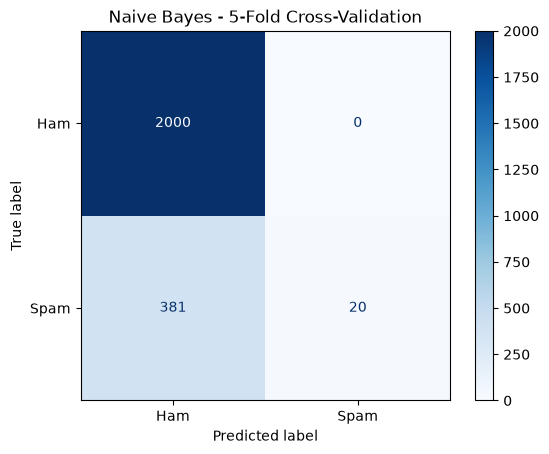

In [59]:
y_cv_pred = cross_val_predict(
    nb_pipeline,
    X_train_processed,
    y_train,
    cv=5
)

print(classification_report(y_train, y_cv_pred))

cm = confusion_matrix(y_train, y_cv_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
).plot(cmap="Blues", values_format="d")

plt.title("Naive Bayes - 5-Fold Cross-Validation")
plt.show()

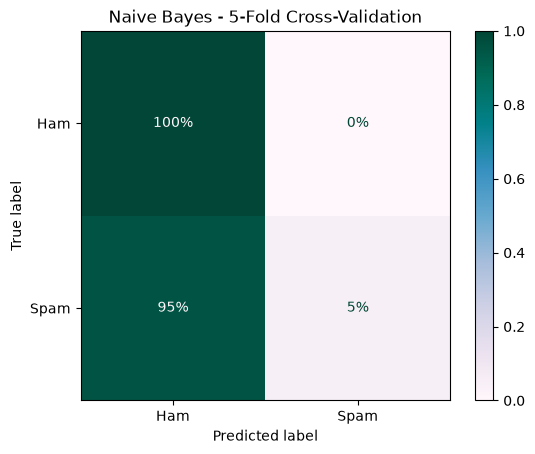

In [70]:
cm = confusion_matrix(y_train, y_cv_pred, normalize="true")

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
).plot(cmap="PuBuGn", values_format=".0%")

plt.title("Naive Bayes - 5-Fold Cross-Validation")
plt.show()

In [23]:
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [24]:
lr_scores = cross_val_score(
    lr_pipeline,
    X_train_processed,
    y_train,
    cv=5,
    scoring="f1"
)

print("F1 scores:", lr_scores)
print("Mean F1:", lr_scores.mean())

F1 scores: [0.94267516 0.96296296 0.91275168 0.9625     0.95424837]
Mean F1: 0.9470276332128105


              precision    recall  f1-score   support

           0       0.98      0.99      0.99      2000
           1       0.97      0.92      0.95       401

    accuracy                           0.98      2401
   macro avg       0.98      0.96      0.97      2401
weighted avg       0.98      0.98      0.98      2401



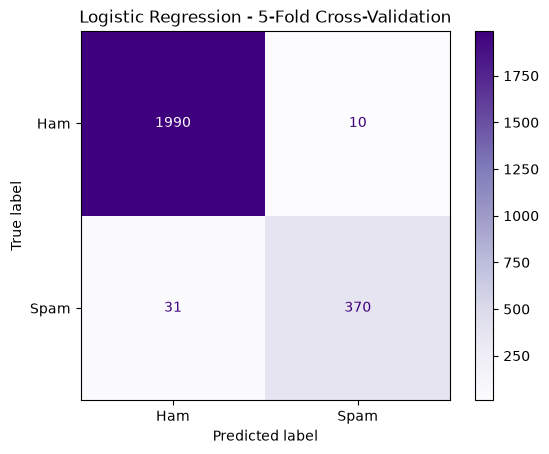

In [25]:
y_lr_pred = cross_val_predict(
    lr_pipeline,
    X_train_processed,
    y_train,
    cv=5
)

print(classification_report(y_train, y_lr_pred))

cm = confusion_matrix(y_train, y_lr_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
).plot(cmap="Purples", values_format="d")

plt.title("Logistic Regression - 5-Fold Cross-Validation")
plt.show()

### Logistic Regression — Confusion Matrix

The confusion matrix helps us visualize how well Logistic Regression classifies both ham and spam emails.

Our model correctly classified:
- **1,990 ham emails** as ham (True Negatives).
- **370 spam emails** as spam (True Positives).

It incorrectly classified:
- **10 ham emails** as spam (False Positives).
- **31 spam emails** as ham (False Negatives).

This explains why the model achieved high precision and recall for both classes. It correctly identifies most ham and spam emails while making relatively few classification errors.

Therefore, Logistic Regression performed significantly better than our Multinomial Naive Bayes baseline.

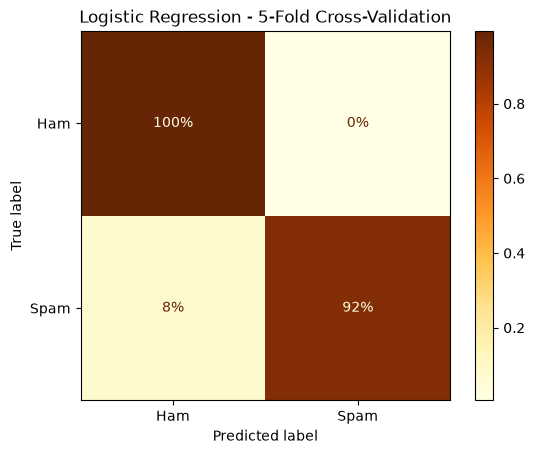

In [69]:
cm = confusion_matrix(y_train, y_lr_pred, normalize="true")
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"],

).plot(cmap="YlOrBr", values_format=".0%")

plt.title("Logistic Regression - 5-Fold Cross-Validation")
plt.show()

In [26]:
y_lr_proba = cross_val_predict(
    lr_pipeline,
    X_train_processed,
    y_train,
    cv=5,
    method="predict_proba"
)[:,1]

In [73]:
precisions, recalls, pr_thresholds = precision_recall_curve(
    y_train, y_lr_proba
)

fpr, tpr, roc_thresholds = roc_curve(
    y_train, y_lr_proba
)

ap_score = average_precision_score(y_train, y_lr_proba)
roc_score = roc_auc_score(y_train, y_lr_proba)

print("Average Precision:", ap_score)
print("ROC-AUC:", roc_score)

Average Precision: 0.9844796948865706
ROC-AUC: 0.9954114713216957


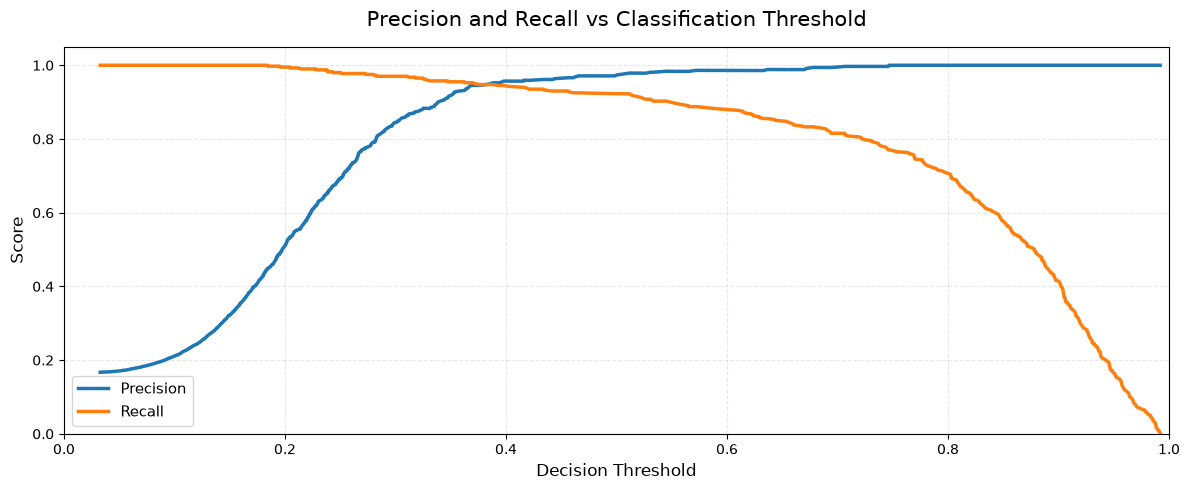

In [89]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    pr_thresholds,
    precisions[:-1],
    label="Precision",
    linewidth=2.5
)

plt.plot(
    pr_thresholds,
    recalls[:-1],
    label="Recall",
    linewidth=2.5
)

plt.title(
    "Precision and Recall vs Classification Threshold",
    fontsize=15,
    pad=15
)

plt.xlabel("Decision Threshold", fontsize=12)
plt.ylabel("Score", fontsize=12)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.grid(True, alpha=0.3, linestyle="--")

plt.legend(
    fontsize=11,
    loc="best",
    frameon=True
)

plt.tight_layout()
plt.show()

### Precision and Recall vs Classification Threshold

The graph illustrates the trade-off between precision and recall as the classification threshold increases.

Around a threshold of 0.38, precision and recall intersect.

- **Below this threshold**: The model has relatively higher recall but lower precision. It identifies more spam emails, but also risks incorrectly classifying ham emails as spam.

- **Above this threshold**: Precision increases while recall decreases. The model becomes more conservative while predicting spam, reducing false positives but missing more actual spam emails.

This happens because increasing the threshold makes it harder for an email to be classified as spam.

Therefore, selecting an appropriate classification threshold depends on the balance we want between precision and recall.

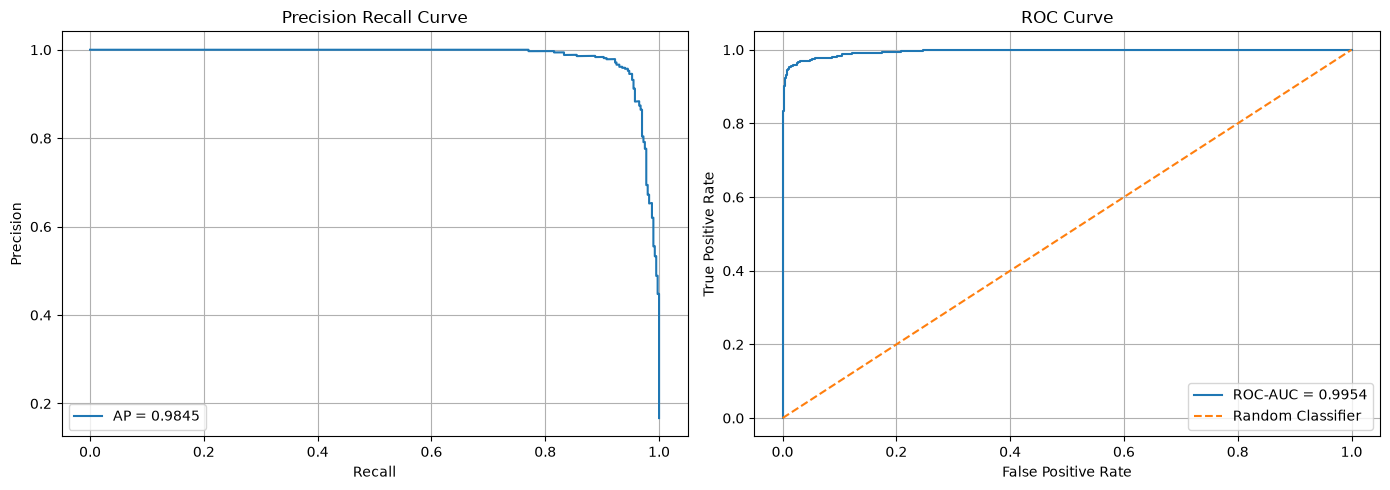

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

axes[0].plot(recalls, precisions, label=f"AP = {ap_score:.4f}")
axes[0].set_title("Precision Recall Curve")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend()
axes[0].grid()

axes[1].plot(fpr, tpr, label=f"ROC-AUC = {roc_score:.4f}")
axes[1].plot([0,1],[0,1], linestyle="--", label="Random Classifier")
axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [27]:
precisions, recalls, thresholds = precision_recall_curve(
    y_train,
    y_lr_proba
)

f1_scores = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-10)
)

best_idx = np.argmax(f1_scores)

print("Best threshold:", thresholds[best_idx])
print("Precision:", precisions[best_idx])
print("Recall:", recalls[best_idx])
print("F1-score:", f1_scores[best_idx])

Best threshold: 0.39809365979954436
Precision: 0.9570707070707071
Recall: 0.9451371571072319
F1-score: 0.9510664993226494


In [29]:
valid_indices = np.where(
    (precisions[:-1] >= 0.95) &
    (recalls[:-1] >= 0.95)
)[0]

if len(valid_indices) > 0:
    print("Thresholds meeting both targets:")

    for idx in valid_indices:
        print(
            f"Threshold: {thresholds[idx]:.4f} | "
            f"Precision: {precisions[idx]:.4f} | "
            f"Recall: {recalls[idx]:.4f}"
        )
else:
    print("No threshold meets both targets.")

No threshold meets both targets.


In [30]:
final_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [35]:
final_pipeline.fit(X_train_processed, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


In [36]:
best_threshold = 0.39809365979954436

In [37]:
y_test_proba = final_pipeline.predict_proba(X_test_processed)[:,1]

y_test_pred = (y_test_proba >= best_threshold).astype(int)

In [38]:
from sklearn.metrics import precision_score, recall_score, f1_score

In [41]:
print(f"Precision score on test set: {precision_score(y_test,y_test_pred):.2f}")
print(f"Recall score on test set: {recall_score(y_test,y_test_pred):.2f} ")
print(f"F1 score on test set: {f1_score(y_test,y_test_pred):.2f}")
print(f"Average Precision score on test set: {average_precision_score(y_test,y_test_pred):.2f}" )
print(f"ROC score on test set: {roc_auc_score(y_test,y_test_pred):.2f}" )

Precision score on test set: 0.95
Recall score on test set: 0.96 
F1 score on test set: 0.96
Average Precision score on test set: 0.92
ROC score on test set: 0.98


In [42]:
import joblib

joblib.dump(final_pipeline, "spam_classifier.pkl")

['spam_classifier.pkl']

In [43]:
joblib.dump(best_threshold, "spam_threshold.pkl")

['spam_threshold.pkl']

In [7]:
import sys
sys.path.insert(0, "..")

In [9]:
from model import predict_email
from preprocessing import preprocess_text

In [34]:
from model import predict_email

result = predict_email(X_train_processed[0])

print(result)

{'prediction': 'Ham', 'spam_probability': 0.05342994868357907, 'threshold': 0.39809365979954436}


In [35]:
import sklearn
print(sklearn.__version__)

1.9.1
